# Hybrid Eval Results Demo

This notebook visualizes downloaded `olmo-eval` results from `local/results/.../all_results.json`.

Edit the config cell to change the result file, regex filters, model-class labels, or plotted evals.

In [58]:
from __future__ import annotations

from collections import defaultdict
import json
import math
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "aesthetics.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import aesthetics as aes

# Checkpoint schedules from ../olmo-eval-internal/local/run_evals.py.
STEPS_A = [0, 7320, 8134, 15454, 16268, 30910, 32537, 61819, 65073, 123639, 130000, 130147]
STEPS_B = [0, 7321, 8135, 15455, 16269, 30911, 32538, 61823, 65077, 123646, 130000, 130154]

pd.set_option("display.max_colwidth", 140)


## Config

In [ ]:
RESULTS_PATH = PROJECT_ROOT / "results" / "jacksonp-hybrid-small-downstream-evals" / "all_results.json"

# Keep only jobs/models matching this regex. Set to None to include every downloaded result.
# RUN_REGEX = r"olmo3-hybrid-gdn-deux_1b_step\d+"
RUN_REGEX = None

# Optional regex applied to eval/task names after flattening. Set to None to include all evals.
TASK_REGEX = None

# Compute per-example score statistics from raw predictions/*.jsonl files.
COMPUTE_RAW_SCORE_STATS = True

# Overlay uncertainty on the line plots. Use "sem" or "ci95_normal".
SHOW_SCORE_ERROR_BARS = True
SCORE_ERROR_BAR = "ci95_normal"

# Name each plotted series from the experiment/model text. First matching pattern wins.
MODEL_CLASS_PATTERNS = [
    (r"olmo3-hybrid-gdn-deux_1b", "hybrid 1B"),
    (r"olmo3-baseline-jacksonp_1b", "transformer 1B"),
    (r"hybrid-small-275m-cx100", "hybrid-small 275M Cx100"),
    (r"pure-gdn-ladder-gate-neg-eig_1b", "GDN± 1B"),
    (r"pure-gdn-ladder-gate-pos-eig_1b", "GDN+ 1B"),
]

# Prefer aggregate suite scores when present; set to None to plot every eval in the file.
PREFERRED_TASKS = [
    # "monoid:commutative:3shot",
    # "monoid:soluble:3shot",
    # "monoid:insoluble:3shot",
    # "grapheme_en",
    "formal_langs_copy",
    "formal_langs_k_dyck",
    "formal_langs_k_shuffle_dyck",

    "formal_langs_k_dyck:k1",
    "formal_langs_k_dyck:k2",
    "formal_langs_k_dyck:k3",
    "formal_langs_k_dyck:k4",
    "formal_langs_k_dyck:k5",
    "formal_langs_k_dyck:k6",

    "formal_langs_k_shuffle_dyck:k1",
    "formal_langs_k_shuffle_dyck:k2",
    "formal_langs_k_shuffle_dyck:k3",
    "formal_langs_k_shuffle_dyck:k4",
    "formal_langs_k_shuffle_dyck:k5",
    "formal_langs_k_shuffle_dyck:k6",

    "formal_langs:v2",
    "formal_langs:v4",
    "formal_langs:v6",
 
    "formal_langs_var_unique:v2",
    "formal_langs_var_unique:v4",
    "formal_langs_var_unique:v6",
    
    "formal_langs_var_reassign_const:v2",
    "formal_langs_var_reassign_const:v4",
    "formal_langs_var_reassign_const:v6",
    
    "formal_langs_var_reassign_var:v2",
    "formal_langs_var_reassign_var:v4",
    "formal_langs_var_reassign_var:v6",
    
    "formal_langs_var_undefined:v2",
    "formal_langs_var_undefined:v4",
    "formal_langs_var_undefined:v6",

    "formal_langs_cube_unique:v2",
    "formal_langs_cube_unique:v4",
    "formal_langs_cube_unique:v6",
    
    "formal_langs_cube_reassign_const:v2",
    "formal_langs_cube_reassign_const:v4",
    "formal_langs_cube_reassign_const:v6",
    
    "formal_langs_cube_reassign_var:v2",
    "formal_langs_cube_reassign_var:v4",
    "formal_langs_cube_reassign_var:v6",
    
    "formal_langs_cube_undefined:v2",
    "formal_langs_cube_undefined:v4",
    "formal_langs_cube_undefined:v6",
]

# PREFERRED_TASKS=None

# Hide the earlier checkpoint in each pre/post learning-rate-decay pair from run_evals.py.
# Keeps step 0 and any unpaired final checkpoint.
FILTER_PRE_DECAY_CHECKPOINTS = True

# If multiple jobs report the same model family / step / eval, keep only the latest experiment_id.
KEEP_LATEST_RUN_PER_MODEL_TASK = True

# If multiple jobs report the same model class / step / eval, average them for cleaner lines.
AGGREGATE_DUPLICATES = True

# Cube-only assignment breakdown plot settings.
# Set CUBE_ASSIGNMENT_BINS = None to plot each exact assignment count separately.
CUBE_ASSIGNMENT_BINS = [(2, 5), (6, 10), (11, 20), (21, 30), (31, 40), (41, 50)]

## Load And Flatten

In [60]:
def extract_step(*values: str | None) -> int | None:
    for value in values:
        if not value:
            continue
        match = re.search(r"(?:^|[_/-])step(\d+)(?:\D|$)", value, flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return None


def model_class_for(experiment_name: str, model: str) -> str:
    haystack = f"{experiment_name} {model}"
    for pattern, label in MODEL_CLASS_PATTERNS:
        if re.search(pattern, haystack, flags=re.IGNORECASE):
            return label

    # Fallback: strip to a stable checkpoint family when the path follows .../<family>/<size>/stepN.
    parts = [part for part in Path(model.rstrip("/")).parts if part]
    if len(parts) >= 2 and re.match(r"step\d+", parts[-1], flags=re.IGNORECASE):
        return "/".join(parts[-3:-1]) if len(parts) >= 3 else parts[-2]
    return experiment_name.split("_step", 1)[0].split("-step", 1)[0]


def metric_value(instance_metrics: dict, metric: str | None) -> float | None:
    value = instance_metrics
    for key in (metric or "").split(":"):
        if not isinstance(value, dict) or key not in value:
            return None
        value = value[key]
    if isinstance(value, int | float) and pd.notna(value) and math.isfinite(value):
        return value
    return None


def task_by_name(result: dict) -> dict[str, dict]:
    return {task["task"]: task for task in result.get("tasks", [])}


def prediction_file_for_task(result: dict, task_name: str, tasks: dict[str, dict]) -> Path | None:
    task = tasks.get(task_name)
    task_hash = task.get("task_hash") if task else None
    if not task_hash:
        return None

    predictions_root = RESULTS_PATH.parent / result["experiment_id"] / "main" / "predictions"
    matches = sorted(predictions_root.glob(f"*/*_{task_hash[-6:]}-predictions.jsonl"))
    return matches[0] if matches else None


def component_tasks_for_aggregate(task_name: str, tasks: dict[str, dict]) -> list[str]:
    if ":" not in task_name:
        return []
    base_task, variant = task_name.rsplit(":", 1)
    prefix = f"{base_task}_"
    suffix = f":{variant}"
    return sorted(
        name
        for name in tasks
        if name.startswith(prefix) and name.endswith(suffix) and name != task_name
    )


def raw_scores_for_task(result: dict, task_name: str, metric: str | None, tasks: dict[str, dict]) -> list[float]:
    path = prediction_file_for_task(result, task_name, tasks)
    if path is None:
        return []

    scores = []
    with path.open() as f:
        for line in f:
            value = metric_value(json.loads(line).get("instance_metrics", {}), metric)
            if value is not None:
                scores.append(float(value))
    return scores


def raw_score_stats(result: dict, task_name: str, metric: str | None, tasks: dict[str, dict]) -> dict:
    scores = raw_scores_for_task(result, task_name, metric, tasks)
    if not scores and metric == "primary_score:average":
        for component_task in component_tasks_for_aggregate(task_name, tasks):
            component_metric = result["summary"][component_task]["metric"]
            scores.extend(raw_scores_for_task(result, component_task, component_metric, tasks))

    if not scores:
        return {
            "score_std": None,
            "score_sem": None,
            "score_ci95_normal": None,
            "score_n": 0,
            "score_sum": None,
            "score_sum_sq": None,
        }

    series = pd.Series(scores, dtype="float64")
    score_n = int(series.count())
    score_std = series.std(ddof=1)
    score_sem = score_std / math.sqrt(score_n) if score_n > 1 else None

    return {
        "score_std": score_std,
        "score_sem": score_sem,
        "score_ci95_normal": 1.96 * score_sem if score_sem is not None else None,
        "score_n": score_n,
        "score_sum": float(series.sum()),
        "score_sum_sq": float((series**2).sum()),
    }


def primary_score_rows(result: dict) -> list[dict]:
    rows = []
    experiment_name = result.get("experiment_name", "")
    model = result.get("model", "")
    step = extract_step(experiment_name, model)
    model_class = model_class_for(experiment_name, model)
    tasks = task_by_name(result)

    for task_name, payload in result.get("summary", {}).items():
        row = {
            "experiment_id": result.get("experiment_id"),
            "experiment_name": experiment_name,
            "experiment_group": result.get("experiment_group"),
            "status": result.get("status"),
            "model": model,
            "model_class": model_class,
            "step": step,
            "task": task_name,
            "metric": payload.get("metric"),
            "score": payload.get("score"),
        }
        if COMPUTE_RAW_SCORE_STATS:
            row.update(raw_score_stats(result, task_name, payload.get("metric"), tasks))
        rows.append(row)
    return rows


raw_results = json.loads(RESULTS_PATH.read_text())
df = pd.DataFrame(row for result in raw_results for row in primary_score_rows(result))
df["score"] = pd.to_numeric(df["score"], errors="coerce")
df["step"] = pd.to_numeric(df["step"], errors="coerce")
if COMPUTE_RAW_SCORE_STATS:
    for column in ["score_std", "score_sem", "score_ci95_normal", "score_n", "score_sum", "score_sum_sq"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

print(f"Loaded {len(raw_results):,} experiments and {len(df):,} eval rows from {RESULTS_PATH}")
df.tail()

Loaded 233 experiments and 3,944 eval rows from /Users/jacksonp/Documents/emergence-analysis/results/jacksonp-hybrid-small-downstream-evals/all_results.json


,experiment_id,experiment_name,experiment_group,status,model,model_class,step,task,metric,score,score_std,score_sem,score_ci95_normal,score_n,score_sum,score_sum_sq
3939,01KTWDN9CAT75CX1VHFYG8NW1Q,pure-gdn-ladder-gate-pos-eig_1b_step65077-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step65077,GDN+ 1B,65077,formal_langs_cube_reassign_const:v2,accuracy:logprob,0.65100,0.476892,0.015081,0.029558,1000,651.0,651.0
3940,01KTWDN9CAT75CX1VHFYG8NW1Q,pure-gdn-ladder-gate-pos-eig_1b_step65077-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step65077,GDN+ 1B,65077,formal_langs_k_shuffle_dyck:k3,accuracy:logprob,0.44000,0.496635,0.015705,0.030782,1000,440.0,440.0
3941,01KTWDN9CAT75CX1VHFYG8NW1Q,pure-gdn-ladder-gate-pos-eig_1b_step65077-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step65077,GDN+ 1B,65077,formal_langs_cube:v2,primary_score:average,0.60675,0.488533,0.007724,0.015140,4000,2427.0,2427.0
3942,01KTWDN9CAT75CX1VHFYG8NW1Q,pure-gdn-ladder-gate-pos-eig_1b_step65077-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step65077,GDN+ 1B,65077,formal_langs_cube:v4,primary_score:average,0.51225,0.499912,0.007904,0.015492,4000,2049.0,2049.0
3943,01KTWDN9CAT75CX1VHFYG8NW1Q,pure-gdn-ladder-gate-pos-eig_1b_step65077-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step65077,GDN+ 1B,65077,formal_langs_cube:v6,primary_score:average,0.45525,0.498056,0.007875,0.015435,4000,1821.0,1821.0


In [61]:
df["task"].unique()

<ArrowStringArray>
[                'formal_langs_k_dyck',    'formal_langs_var_reassign_var:v2',
         'formal_langs_k_shuffle_dyck',       'formal_langs_var_undefined:v6',
  'formal_langs_var_reassign_const:v6',    'formal_langs_var_reassign_var:v6',
       'formal_langs_var_undefined:v2',          'formal_langs_var_unique:v4',
  'formal_langs_var_reassign_const:v2',       'formal_langs_var_undefined:v4',
  'formal_langs_var_reassign_const:v4',          'formal_langs_var_unique:v6',
          'formal_langs_var_unique:v2',    'formal_langs_var_reassign_var:v4',
                   'formal_langs_copy',                     'formal_langs:v2',
                     'formal_langs:v4',                     'formal_langs:v6',
   'formal_langs_cube_reassign_var:v6',         'formal_langs_cube_unique:v6',
 'formal_langs_cube_reassign_const:v4',      'formal_langs_cube_undefined:v6',
      'formal_langs_cube_undefined:v2', 'formal_langs_cube_reassign_const:v2',
         'formal_langs_cube_uniqu

## Apply Filters

In [62]:
plot_df = df.copy()

if RUN_REGEX:
    run_mask = (
        plot_df["experiment_name"].str.contains(RUN_REGEX, case=False, regex=True, na=False)
        | plot_df["model"].str.contains(RUN_REGEX, case=False, regex=True, na=False)
    )
    plot_df = plot_df[run_mask]

if TASK_REGEX:
    plot_df = plot_df[plot_df["task"].str.contains(TASK_REGEX, case=False, regex=True, na=False)]

if PREFERRED_TASKS:
    preferred = plot_df[plot_df["task"].isin(PREFERRED_TASKS)]
    if not preferred.empty:
        plot_df = preferred

plot_df = plot_df.dropna(subset=["step", "score"])


def pre_decay_checkpoints(steps: list[int]) -> set[int]:
    # Ignore the initial checkpoint, then treat complete adjacent entries as pre/post decay pairs.
    paired_steps = steps[1:]
    complete_pairs = len(paired_steps) // 2
    return {paired_steps[2 * pair_index] for pair_index in range(complete_pairs)}


PRE_DECAY_CHECKPOINTS = pre_decay_checkpoints(STEPS_A) | pre_decay_checkpoints(STEPS_B)
if FILTER_PRE_DECAY_CHECKPOINTS:
    pre_decay_mask = plot_df["step"].astype(int).isin(PRE_DECAY_CHECKPOINTS)
    plot_df = plot_df[~pre_decay_mask]

task_order = None
if PREFERRED_TASKS:
    available_tasks = set(plot_df["task"])
    task_order = []
    for task in PREFERRED_TASKS:
        if task in available_tasks and task not in task_order:
            task_order.append(task)
    if task_order:
        plot_df["task"] = pd.Categorical(plot_df["task"], categories=task_order, ordered=True)

plot_df = plot_df.sort_values(["task", "model_class", "step"])

if KEEP_LATEST_RUN_PER_MODEL_TASK:
    latest_sort_columns = ["task", "metric", "model_class", "step", "experiment_id"]
    latest_key_columns = ["task", "metric", "model_class", "step"]
    plot_df = (
        plot_df.sort_values(latest_sort_columns, ascending=[True, True, True, True, False])
        .drop_duplicates(latest_key_columns, keep="first")
        .sort_values(["task", "model_class", "step"])
    )

if AGGREGATE_DUPLICATES and not KEEP_LATEST_RUN_PER_MODEL_TASK:
    aggregate_spec = {
        "score": ("score", "mean"),
        "runs": ("experiment_id", "nunique"),
    }
    if COMPUTE_RAW_SCORE_STATS:
        aggregate_spec.update(
            score_n=("score_n", "sum"),
            score_sum=("score_sum", lambda values: values.sum(min_count=1)),
            score_sum_sq=("score_sum_sq", lambda values: values.sum(min_count=1)),
        )

    plot_df = plot_df.groupby(["task", "metric", "model_class", "step"], as_index=False).agg(**aggregate_spec)

    if COMPUTE_RAW_SCORE_STATS:
        variance = (
            plot_df["score_sum_sq"] - (plot_df["score_sum"] ** 2 / plot_df["score_n"])
        ) / (plot_df["score_n"] - 1)
        plot_df["score_std"] = variance.clip(lower=0).pow(0.5)
        plot_df.loc[plot_df["score_n"] <= 1, "score_std"] = pd.NA
        plot_df["score_sem"] = plot_df["score_std"] / plot_df["score_n"].pow(0.5)
        plot_df["score_ci95_normal"] = 1.96 * plot_df["score_sem"]
else:
    plot_df["runs"] = 1

def add_score_error_bounds(plot_df: pd.DataFrame, error_bar: str) -> pd.DataFrame:
    error_columns = {
        "sem": "score_sem",
        "ci95_normal": "score_ci95_normal",
    }
    if not SHOW_SCORE_ERROR_BARS:
        return plot_df
    if error_bar not in error_columns:
        raise ValueError(f"Unknown SCORE_ERROR_BAR={error_bar!r}. Use one of {sorted(error_columns)}.")

    error_column = error_columns[error_bar]
    if error_column not in plot_df.columns:
        return plot_df

    plot_df = plot_df.copy()
    plot_df["score_error"] = plot_df[error_column]
    plot_df["score_error_low"] = (plot_df["score"] - (plot_df["score"] - plot_df["score_error"]).clip(lower=0))
    plot_df["score_error_high"] = ((plot_df["score"] + plot_df["score_error"]).clip(upper=1) - plot_df["score"])
    return plot_df


plot_df = add_score_error_bounds(plot_df, SCORE_ERROR_BAR)


print(f"Plotting {len(plot_df):,} rows across {plot_df['task'].nunique():,} evals")
display(plot_df.head(20))

if plot_df.empty:
    raise ValueError("No rows matched the current filters. Loosen RUN_REGEX, TASK_REGEX, or PREFERRED_TASKS.")

Plotting 1,176 rows across 42 evals


,experiment_id,experiment_name,experiment_group,status,model,model_class,step,task,metric,score,score_std,score_sem,score_ci95_normal,score_n,score_sum,score_sum_sq,runs,score_error,score_error_low,score_error_high
1141,01KTS9XBWF7K1YVHZXVE4Z7WD9,pure-gdn-ladder-gate-pos-eig_1b_step0-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step0,GDN+ 1B,0,formal_langs_copy,accuracy:logprob,0.262,0.439943,0.013912,0.027268,1000,262.0,262.0,1,0.027268,0.027268,0.027268
1271,01KTS9XK04DDT185E14SC34685,pure-gdn-ladder-gate-pos-eig_1b_step8135-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step8135,GDN+ 1B,8135,formal_langs_copy,accuracy:logprob,0.976,0.153126,0.004842,0.009491,1000,976.0,976.0,1,0.009491,0.009491,0.009491
1334,01KTS9XT4YG3Z9CX9XSK2H243T,pure-gdn-ladder-gate-pos-eig_1b_step16269-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step16269,GDN+ 1B,16269,formal_langs_copy,accuracy:logprob,0.982,0.133018,0.004206,0.008245,1000,982.0,982.0,1,0.008245,0.008245,0.008245
1411,01KTS9Y1C6JJGJ1TH4YEMQHXBT,pure-gdn-ladder-gate-pos-eig_1b_step32538-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step32538,GDN+ 1B,32538,formal_langs_copy,accuracy:logprob,0.979,0.143456,0.004536,0.008891,1000,979.0,979.0,1,0.008891,0.008891,0.008891
1487,01KTS9Y8QADEYD44ZTA3RQNBV6,pure-gdn-ladder-gate-pos-eig_1b_step65077-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step65077,GDN+ 1B,65077,formal_langs_copy,accuracy:logprob,0.977,0.149978,0.004743,0.009296,1000,977.0,977.0,1,0.009296,0.009296,0.009296
1523,01KTS9YFH47PZEXKRZ6DNZENMZ,pure-gdn-ladder-gate-pos-eig_1b_step130000-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step130000,GDN+ 1B,130000,formal_langs_copy,accuracy:logprob,0.973,0.162164,0.005128,0.010051,1000,973.0,973.0,1,0.010051,0.010051,0.010051
1541,01KTS9YK0SX0YNHF0CTAGDJH2V,pure-gdn-ladder-gate-pos-eig_1b_step130154-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step130154,GDN+ 1B,130154,formal_langs_copy,accuracy:logprob,0.973,0.162164,0.005128,0.010051,1000,973.0,973.0,1,0.010051,0.010051,0.010051
74,01KTS9JFFJKZE8XFMW26G2XEJX,pure-gdn-ladder-gate-neg-eig_1b_step0-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-neg-eig/1B/step0,GDN± 1B,0,formal_langs_copy,accuracy:logprob,0.260,0.438854,0.013878,0.027200,1000,260.0,260.0,1,0.027200,0.027200,0.027200
140,01KTS9JPE8KCPAP4227MS63FR8,pure-gdn-ladder-gate-neg-eig_1b_step8135-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-neg-eig/1B/step8135,GDN± 1B,8135,formal_langs_copy,accuracy:logprob,0.983,0.129336,0.004090,0.008016,1000,983.0,983.0,1,0.008016,0.008016,0.008016
206,01KTS9JXGZ5R78NHK79FFDGYQS,pure-gdn-ladder-gate-neg-eig_1b_step16269-formal_langs_v2-formal_langs_v4-and-1-more,jacksonp-hybrid-small-downstream-evals,succeeded,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-neg-eig/1B/step16269,GDN± 1B,16269,formal_langs_copy

## Accuracy By Training Step

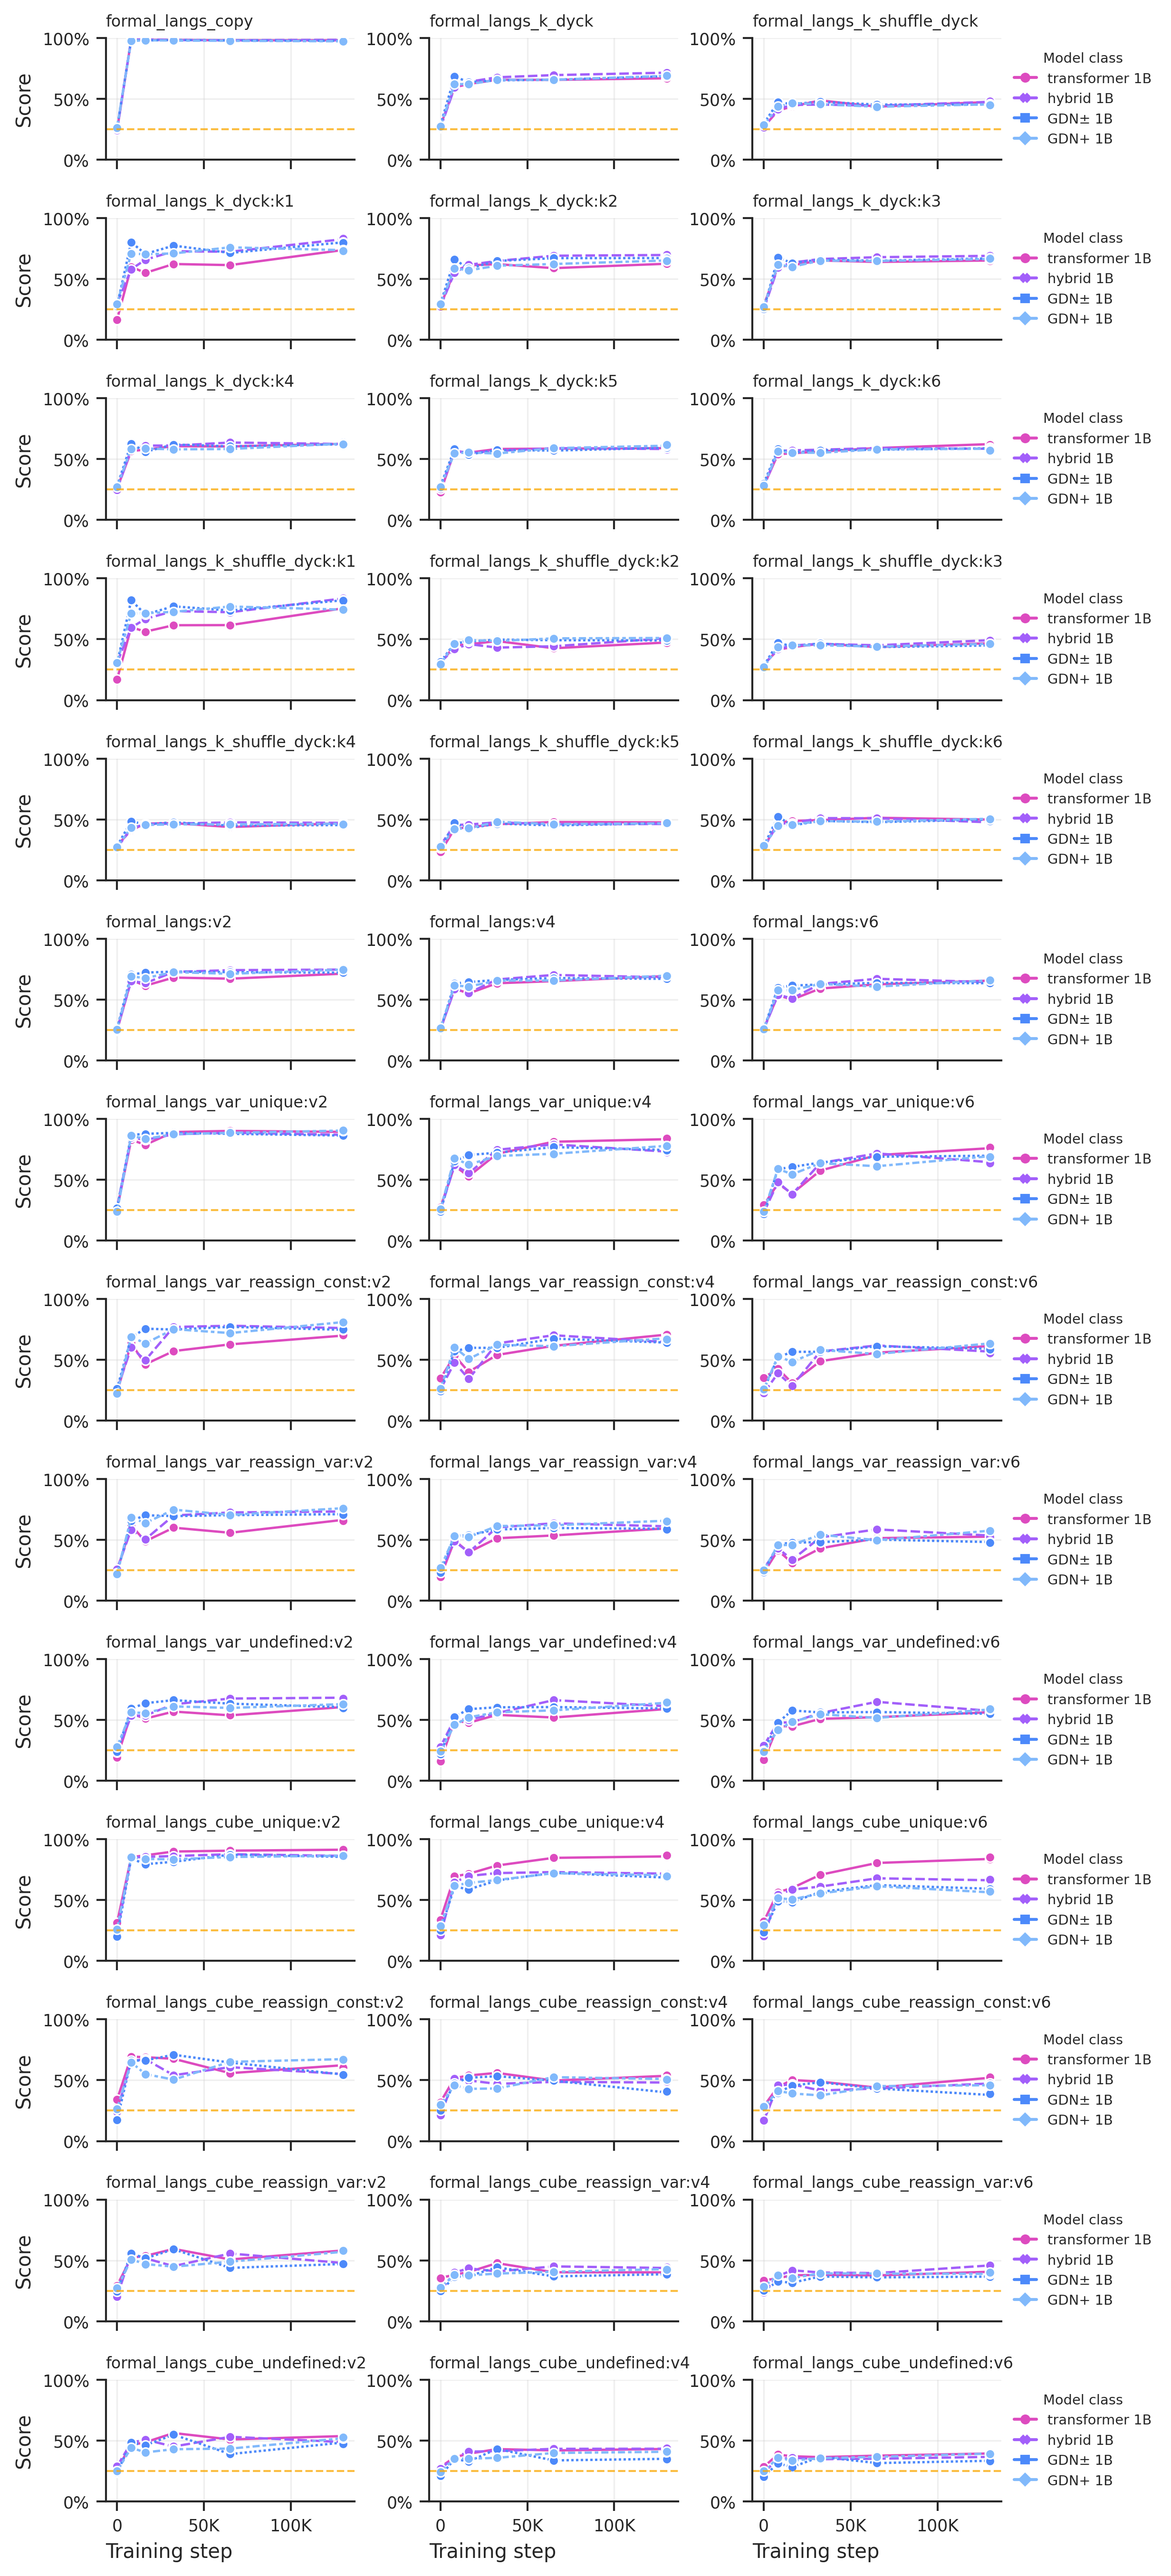

In [66]:
n_tasks = plot_df["task"].nunique()
col_wrap = 2 if n_tasks <= 4 else 3
facet_cols = min(n_tasks, col_wrap)
facet_height = (
    aes.FIG_HEIGHT_DOUBLE_ROW_IN
    if n_tasks <= col_wrap
    else aes.FIG_HEIGHT_SINGLE_ROW_IN
)
facet_aspect = (aes.PAPER_WIDTH_IN * 1.3 / facet_cols) / facet_height

MODEL_CLASS_PALETTE = aes.set_palette(
    key="models",
    family="OLMo variants",
    color="blend:#fb4b4e,#ce4bfa,#4b88fa,#9cd2fc,#cccccc",
    names=[
        "transformer 1B",
        "hybrid 1B",
        "GDN± 1B",
        "GDN+ 1B",
        "hybrid-small 275M Cx100",
    ],
    display_name=lambda _family, name: name,
)

hue_order = [name for name in MODEL_CLASS_PALETTE if name in set(plot_df["model_class"])]

g = sns.relplot(
    data=plot_df,
    x="step",
    y="score",
    hue="model_class",
    hue_order=hue_order,
    palette=MODEL_CLASS_PALETTE,
    style="model_class",
    style_order=hue_order,
    col="task",
    col_wrap=col_wrap,
    kind="line",
    marker="o",
    facet_kws={"sharey": False, "sharex": True},
    col_order=task_order,
    legend=False,
    height=facet_height,
    aspect=facet_aspect,
)
g.set_axis_labels("Training step", "Score")
g.set_titles("{col_name}", fontweight="regular", size=8.0)
g.set(ylim=(0, 1))

if SHOW_SCORE_ERROR_BARS and {"score_error_low", "score_error_high"}.issubset(plot_df.columns):
    for task, ax in zip(g.col_names, g.axes.flat, strict=False):
        task_df = plot_df[plot_df["task"].astype(str) == str(task)]
        for model_class, model_df in task_df.groupby("model_class", observed=True):
            model_df = model_df.dropna(subset=["score_error_low", "score_error_high"]).sort_values("step")
            if model_df.empty:
                continue
            ax.errorbar(
                model_df["step"],
                model_df["score"],
                yerr=[model_df["score_error_low"], model_df["score_error_high"]],
                fmt="none",
                color=MODEL_CLASS_PALETTE[model_class],
                alpha=0.35,
                elinewidth=0.8,
                capsize=1.5,
                capthick=0.8,
                zorder=1,
            )

MODEL_CLASS_MARKERS = dict(zip(hue_order, ["o", "X", "s", "D", "P"], strict=False))
legend_handles = [
    plt.Line2D(
        [0],
        [0],
        color=MODEL_CLASS_PALETTE[model_class],
        marker=MODEL_CLASS_MARKERS.get(model_class, "o"),
        linewidth=1.5,
        markersize=4,
        label=model_class,
    )
    for model_class in hue_order
]

MONOID_CHANCE_BY_BASE_TASK = {
    "monoid_s2": 1 / 2,
    "monoid_a3": 1 / 3,
    # All other current monoid tasks use 4 choices: gold + 3 distractors.
}

COMMUTATIVE_MONOIDS = [
    "monoid_s2",
    "monoid_a3",
    "monoid_z6",
    "monoid_z12",
    "monoid_z24",
    "monoid_z60",
    "monoid_z120",
    "monoid_z360",
    "monoid_z720",
]
SOLUBLE_MONOIDS = ["monoid_s3", "monoid_s4", "monoid_a4"]
INSOLUBLE_MONOIDS = ["monoid_s5", "monoid_s6", "monoid_a5", "monoid_a6"]


def monoid_task_chance(task: str) -> float | None:
    base_task = task.split(":", 1)[0]
    if not base_task.startswith("monoid_"):
        return None
    return MONOID_CHANCE_BY_BASE_TASK.get(base_task, 1 / 4)


def mean_chance(tasks: list[str]) -> float:
    return sum(monoid_task_chance(task) for task in tasks) / len(tasks)


CHANCE_BY_TASK = defaultdict(
    lambda: 0.25,
    {
        "monoid:commutative:3shot": mean_chance(COMMUTATIVE_MONOIDS),
        "monoid:soluble:3shot": mean_chance(SOLUBLE_MONOIDS),
        "monoid:insoluble:3shot": mean_chance(INSOLUBLE_MONOIDS),
    },
)

for task, ax in zip(g.col_names, g.axes.flat, strict=False):
    chance = monoid_task_chance(task)
    if chance is None:
        chance = CHANCE_BY_TASK[task]
    ax.axhline(
        chance,
        color=aes.NONSEMANTIC_COLOR,
        linestyle="--",
        linewidth=1,
        alpha=0.75,
    )

    ax.xaxis.set_major_formatter(aes.COMPACT_NUMBER_FORMATTER)
    ax.yaxis.set_major_formatter(aes.PCT_FORMATTER)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

for row_start in range(0, len(g.axes.flat), col_wrap):
    row_axes = [ax for ax in g.axes.flat[row_start : row_start + col_wrap] if ax.get_visible()]
    if not row_axes:
        continue
    row_axes[-1].legend(
        handles=legend_handles,
        title="Model class",
        loc="center left",
        bbox_to_anchor=(1.03, 0.5),
        frameon=False,
        fontsize="x-small",
        title_fontsize="x-small",
        borderaxespad=0.0,
        handlelength=1.6,
    )
plt.show()


## Cube Tasks By Assignment Count

In [1]:
def request_file_for_task(result: dict, task_name: str, tasks: dict[str, dict]) -> Path | None:
    task = tasks.get(task_name)
    task_hash = task.get("task_hash") if task else None
    if not task_hash:
        return None

    requests_root = RESULTS_PATH.parent / result["experiment_id"] / "main" / "requests"
    matches = sorted(requests_root.glob(f"*/*_{task_hash[-6:]}-requests.jsonl"))
    return matches[0] if matches else None


def cube_task_parts(task_name: str) -> tuple[str | None, str | None]:
    match = re.fullmatch(r"formal_langs_cube_(.+):(v[246])", task_name)
    if not match:
        return None, None
    task_variant = match.group(1).replace("_", " ")
    return task_variant, match.group(2)


def assignment_group_for(num_assignments: int) -> str:
    if CUBE_ASSIGNMENT_BINS is None:
        return str(num_assignments)
    for low, high in CUBE_ASSIGNMENT_BINS:
        if low <= num_assignments <= high:
            return f"{low}-{high}" if low != high else str(low)
    return str(num_assignments)


def cube_assignment_rows_for(row: pd.Series, result: dict) -> list[dict]:
    task_name = str(row["task"])
    task_variant, version = cube_task_parts(task_name)
    if task_variant is None:
        return []

    tasks = task_by_name(result)
    request_path = request_file_for_task(result, task_name, tasks)
    prediction_path = prediction_file_for_task(result, task_name, tasks)
    if request_path is None or prediction_path is None:
        return []

    metric = row["metric"]
    scores_by_assignment_group = defaultdict(list)
    assignment_values_by_group = defaultdict(set)
    with request_path.open() as request_file, prediction_path.open() as prediction_file:
        for request_line, prediction_line in zip(request_file, prediction_file, strict=False):
            request_doc = json.loads(request_line).get("doc", {})
            num_assignments = request_doc.get("num_assignments")
            if num_assignments is None:
                continue

            prediction = json.loads(prediction_line)
            score = metric_value(prediction.get("instance_metrics", {}), metric)
            if score is None:
                continue

            num_assignments = int(num_assignments)
            assignment_group = assignment_group_for(num_assignments)
            scores_by_assignment_group[assignment_group].append(float(score))
            assignment_values_by_group[assignment_group].add(num_assignments)

    rows = []
    for assignment_group, scores in scores_by_assignment_group.items():
        series = pd.Series(scores, dtype="float64")
        score_n = int(series.count())
        score = float(series.mean())
        score_std = series.std(ddof=1)
        score_sem = score_std / math.sqrt(score_n) if score_n > 1 else None
        assignment_values = sorted(assignment_values_by_group[assignment_group])
        rows.append(
            {
                "experiment_id": row["experiment_id"],
                "model_class": row["model_class"],
                "step": row["step"],
                "task": task_name,
                "cube_task": task_variant,
                "version": version,
                "assignment_group": assignment_group,
                "assignment_min": assignment_values[0],
                "assignment_max": assignment_values[-1],
                "score": score,
                "score_std": score_std,
                "score_sem": score_sem,
                "score_ci95_normal": 1.96 * score_sem if score_sem is not None else None,
                "score_n": score_n,
            }
        )
    return rows


result_by_id = {result["experiment_id"]: result for result in raw_results}
cube_source_df = plot_df[
    plot_df["task"].astype(str).str.fullmatch(r"formal_langs_cube_.+:v[246]")
].copy()

cube_assignment_df = pd.DataFrame(
    cube_row
    for _, row in cube_source_df.iterrows()
    for cube_row in cube_assignment_rows_for(row, result_by_id[row["experiment_id"]])
)

if cube_assignment_df.empty:
    raise ValueError("No cube assignment metadata matched the current filters.")

cube_assignment_df["step"] = pd.to_numeric(cube_assignment_df["step"], errors="coerce")
cube_assignment_df = cube_assignment_df.sort_values(
    ["version", "cube_task", "assignment_group", "model_class", "step"]
)
cube_assignment_df = add_score_error_bounds(cube_assignment_df, SCORE_ERROR_BAR)

assignment_order = sorted(
    cube_assignment_df["assignment_group"].dropna().unique(),
    key=lambda label: int(str(label).split("-", 1)[0]),
)
version_order = [version for version in ["v2", "v4", "v6"] if version in set(cube_assignment_df["version"])]
cube_task_order = [
    task for task in ["unique", "undefined", "reassign const", "reassign var"]
    if task in set(cube_assignment_df["cube_task"])
]
hue_order = [name for name in MODEL_CLASS_PALETTE if name in set(cube_assignment_df["model_class"])]
assignment_markers = ["o", "X", "s", "D", "P", "^", "v", "<", ">"]
assignment_dashes = ["", (2, 1), (4, 1), (1, 1), (3, 1, 1, 1), (5, 2), (2, 2, 1, 2), (6, 1), (3, 3)]

print(
    f"Plotting {len(cube_assignment_df):,} cube assignment rows across "
    f"{cube_assignment_df['task'].nunique():,} cube tasks and "
    f"{cube_assignment_df['assignment_group'].nunique():,} assignment groups"
)
display(cube_assignment_df.head(20))

g_cube = sns.relplot(
    data=cube_assignment_df,
    x="step",
    y="score",
    hue="model_class",
    hue_order=hue_order,
    palette=MODEL_CLASS_PALETTE,
    style="assignment_group",
    style_order=assignment_order,
    col="cube_task",
    col_order=cube_task_order,
    row="version",
    row_order=version_order,
    kind="line",
    markers=assignment_markers[: len(assignment_order)],
    dashes=assignment_dashes[: len(assignment_order)],
    markersize=3,
    linewidth=1.1,
    facet_kws={"sharey": False, "sharex": True},
    legend=False,
    height=aes.FIG_HEIGHT_SINGLE_ROW_IN,
    aspect=(aes.PAPER_WIDTH_IN * 1.3 / max(1, len(cube_task_order))) / aes.FIG_HEIGHT_SINGLE_ROW_IN,
)
g_cube.set_axis_labels("Training step", "Score")
g_cube.set_titles(row_template="{row_name}", col_template="{col_name}", fontweight="regular", size=8.0)
g_cube.set(ylim=(0, 1))

if SHOW_SCORE_ERROR_BARS and {"score_error_low", "score_error_high"}.issubset(cube_assignment_df.columns):
    for (version, cube_task), ax in g_cube.axes_dict.items():
        facet_df = cube_assignment_df[
            (cube_assignment_df["version"] == version)
            & (cube_assignment_df["cube_task"] == cube_task)
        ]
        for (model_class, assignment_group), model_df in facet_df.groupby(
            ["model_class", "assignment_group"], observed=True
        ):
            model_df = model_df.dropna(subset=["score_error_low", "score_error_high"]).sort_values("step")
            if model_df.empty:
                continue
            ax.errorbar(
                model_df["step"],
                model_df["score"],
                yerr=[model_df["score_error_low"], model_df["score_error_high"]],
                fmt="none",
                color=MODEL_CLASS_PALETTE[model_class],
                alpha=0.18,
                elinewidth=0.6,
                capsize=1.0,
                capthick=0.6,
                zorder=1,
            )

for ax in g_cube.axes.flat:
    ax.axhline(0.25, color=aes.NONSEMANTIC_COLOR, linestyle="--", linewidth=1, alpha=0.75)
    ax.xaxis.set_major_formatter(aes.COMPACT_NUMBER_FORMATTER)
    ax.yaxis.set_major_formatter(aes.PCT_FORMATTER)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

model_handles = [
    plt.Line2D([0], [0], color=MODEL_CLASS_PALETTE[model_class], marker="o", linewidth=1.5, markersize=4, label=model_class)
    for model_class in hue_order
]
assignment_handles = [
    plt.Line2D(
        [0],
        [0],
        color=aes.NONSEMANTIC_COLOR,
        marker=marker,
        linestyle=(0, dash) if dash else "-",
        linewidth=1.0,
        markersize=4,
        label=f"{label} assignments",
    )
    for label, marker, dash in zip(assignment_order, assignment_markers, assignment_dashes, strict=False)
]

g_cube.figure.legend(
    handles=model_handles,
    title="Model class",
    loc="upper center",
    bbox_to_anchor=(0.43, 1.02),
    ncol=max(1, min(3, len(model_handles))),
    frameon=False,
    fontsize="x-small",
    title_fontsize="x-small",
)
g_cube.figure.legend(
    handles=assignment_handles,
    title="Assignment group",
    loc="upper center",
    bbox_to_anchor=(0.78, 1.02),
    ncol=max(1, min(3, len(assignment_handles))),
    frameon=False,
    fontsize="x-small",
    title_fontsize="x-small",
)

plt.show()


NameError: name 'raw_results' is not defined

## Coverage Checks

In [ ]:
coverage = (
    df.assign(matches_run=lambda x: x["experiment_name"].str.contains(RUN_REGEX or ".*", case=False, regex=True, na=False))
    .drop_duplicates(["experiment_id", "experiment_name", "model", "step", "model_class"])
    .sort_values(["matches_run", "model_class", "step"], ascending=[False, True, True])
)

display(
    coverage[["matches_run", "experiment_name", "model_class", "step", "model", "status"]]
    .reset_index(drop=True)tt
)

display(
    df.groupby("task", as_index=False)
    .agg(rows=("score", "size"), models=("model_class", "nunique"), steps=("step", "nunique"))
    .sort_values(["rows", "task"], ascending=[False, True])
)

,matches_run,experiment_name,model_class,step,model,status
0,True,pure-gdn-ladder-gate-pos-eig_1b_step0-formal_langs_cube_v2-formal_langs_cube_v4-and-1-more,GDN+ 1B,0,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step0,succeeded
1,True,pure-gdn-ladder-gate-pos-eig_1b_step0-formal_langs_v2-formal_langs_v4-and-1-more,GDN+ 1B,0,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step0,succeeded
2,True,pure-gdn-ladder-gate-pos-eig_1b_step0-formal_langs_copy-formal_langs_k_dyck-and-5-more-d4cd,GDN+ 1B,0,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step0,succeeded
3,True,pure-gdn-ladder-gate-pos-eig_1b_step0-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,GDN+ 1B,0,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step0,succeeded
4,True,pure-gdn-ladder-gate-pos-eig_1b_step7321-formal_langs_cube_v2-formal_langs_cube_v4-and-1-more,GDN+ 1B,7321,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/pure-gdn-ladder-gate-pos-eig/1B/step7321,succeeded
...,...,...,...,...,...,...
228,True,olmo3-baseline-jacksonp_1b_step130147-formal_langs_cube_v2-formal_langs_cube_v4-and-13-more,transformer 1B,130147,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/olmo3-baseline-jacksonp/1B/step130147,succeeded
229,True,olmo3-baseline-jacksonp_1b_step130147-formal_langs_cube_v2-formal_langs_cube_v4-and-1-more,transformer 1B,130147,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/olmo3-baseline-jacksonp/1B/step130147,succeeded
230,True,olmo3-baseline-jacksonp_1b_step130147-formal_langs_copy-formal_langs_k_dyck-and-5-more,transformer 1B,130147,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/olmo3-baseline-jacksonp/1B/step130147,succeeded
231,True,olmo3-baseline-jacksonp_1b_step130147-monoid_commutative_3shot-monoid_soluble_3shot-and-2-more-72af,transformer 1B,130147,/weka/oe-training-default/ai2-llm/checkpoints/jacksonp/olmo3-baseline-jacksonp/1B/step130147,succeeded


,task,rows,models,steps
4,formal_langs_cube:v2,94,4,22
5,formal_langs_cube:v4,94,4,22
6,formal_langs_cube:v6,94,4,22
7,formal_langs_cube_reassign_const:v2,94,4,22
8,formal_langs_cube_reassign_const:v4,94,4,22
...,...,...,...,...
68,monoid_z720:3shot,41,3,22
33,formal_langs_var_reassign_const,36,4,17
37,formal_langs_var_reassign_var,36,4,17
41,formal_langs_var_undefined,36,4,17
